# Week 5 - Transfer Learning
**Introduction to Applied AI | BS 8th Semester | Department of Electronics**
Project 2: Deep Learning Applications

**Name:** Muhammad Raheel Ijaz

**Project Overview**

**Environment:** local Jupyter Notebook, CPU only (no NVIDIA GPU), PyTorch + torchvision. Dataset: Intel Image Classification (Kaggle, puneet6060), downloaded into the `data` folder.

## Part 1: The Data, and an Image as Numbers

### Task 1.1: Imports, GPU check, and class counts

In [1]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # cuda = NVIDIA GPU (fast); cpu = works, but much slower
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU found: training will run on the CPU (expect roughly 10-30+ min per epoch).')

Device: cpu
No GPU found: training will run on the CPU (expect roughly 10-30+ min per epoch).


In [2]:
# Local setup: dataset lives in ./data (next to this notebook). Output folders are created here.
BASE = os.getcwd()
IMG_DIR = os.path.join(BASE, 'images')
MODEL_DIR = os.path.join(BASE, 'models')
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
NUM_WORKERS = 0 if os.name == 'nt' else 2   # 0 is the stable choice on Windows

def find_split(root, name):
    """Find the folder that directly contains the 6 class folders for seg_train / seg_test."""
    for dirpath, dirnames, _ in os.walk(root):
        if os.path.basename(dirpath) == name and 'forest' in dirnames and 'sea' in dirnames:
            return dirpath
    raise FileNotFoundError(f'Could not find {name} with class folders under {root}. '
                            f'Put the extracted dataset inside the data folder.')

DATA_ROOT = os.path.join(BASE, 'data')
TRAIN_DIR = find_split(DATA_ROOT, 'seg_train')
TEST_DIR = find_split(DATA_ROOT, 'seg_test')
print('TRAIN_DIR =', TRAIN_DIR)
print('TEST_DIR  =', TEST_DIR)
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

TRAIN_DIR = D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications\data\seg_train\seg_train
TEST_DIR  = D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications\data\seg_test\seg_test
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


**Check:** the device printed `cpu`. This PC has no CUDA GPU, so every cell ran on the CPU (about 17 to 50 minutes per epoch instead of about one minute on a T4). The code is identical to the GPU version; only the speed differs.

### Task 1.2: Look at the images, then at the numbers

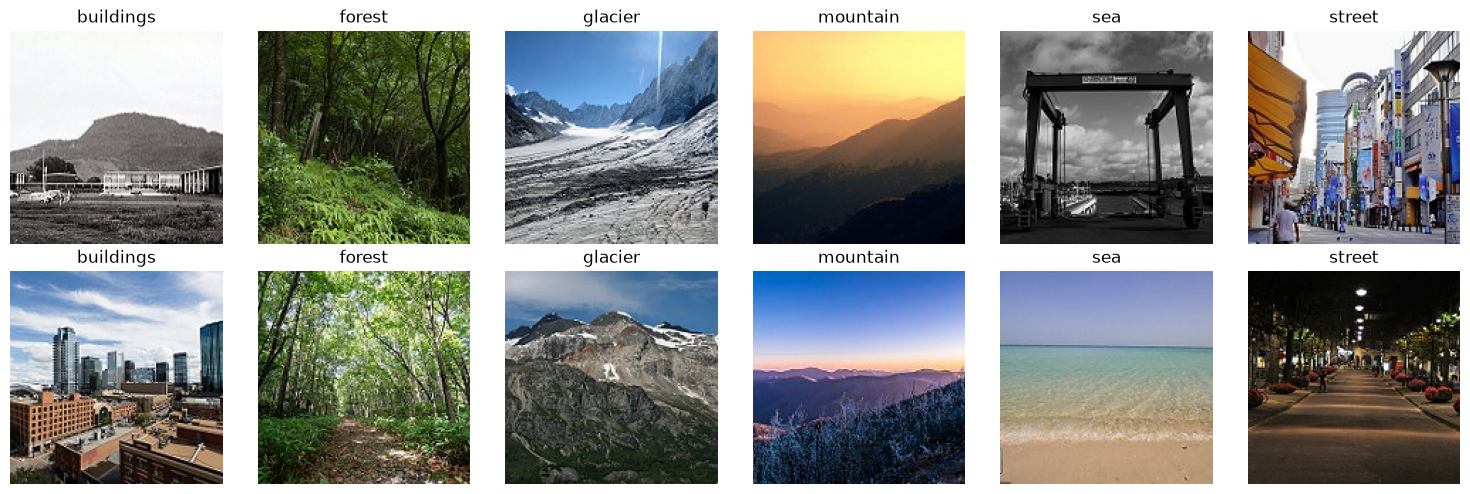

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [3]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, 'sample_grid.png'), dpi=120, bbox_inches='tight')
plt.show()
arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

### Write it - Part 1
**Class counts:** the training folder has 14,034 images and the test folder 3,000, in 6 classes. The data is fairly balanced.

| class | train | test |
|---|---|---|
| buildings | 2,191 | 437 |
| forest | 2,271 | 474 |
| glacier | 2,404 | 553 |
| mountain | 2,512 | 525 |
| sea | 2,274 | 510 |
| street | 2,382 | 501 |

**Image facts:** an image is a tensor of shape (H, W, C) = **(150, 150, 3)**, dtype **uint8**, values from **0 to 255**. The top-left 3x3 of the red channel is [[8, 6, 3], [6, 5, 4], [5, 5, 5]]: values near 0 mean a very dark corner (this is the night-time street photo, the last image in the grid).

**Which classes look most similar by eye:** *glacier* and *mountain*. In the grid, the second glacier image is a snow-covered rocky peak that could easily be labelled mountain, and both classes share rock, snow and sky. *Buildings* and *street* are a second similar pair: both show multi-storey facades from ground level.

**My prediction (made from the sample grid, before running Part 6):** the model will confuse **glacier with mountain** most, because snow, rock and peaks appear in both. The runner-up will be buildings vs street.

## Part 2: Convolution and Parameters by Hand

### Task 2.1: Reproduce the lecture's convolution

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


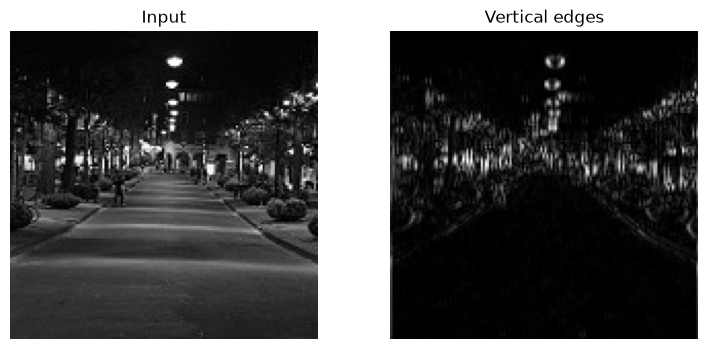

In [4]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]
# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.savefig(os.path.join(IMG_DIR, 'edges.png'), dpi=120, bbox_inches='tight')
plt.show()

### Task 2.2: Why convolutions, in numbers

In [5]:
def count(m):
    return sum(p.numel() for p in m.parameters())
conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64   : {count(conv):,} parameters')  # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')
t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')  # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))
print('Ratio dense / conv =', count(dense) / count(conv))

Conv 3x3, 3 -> 64   : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)
Ratio dense / conv = 19286.0


### Write it - Part 2
**Convolution check:** the printed output is three rows of `[30, 30, 0]`, exactly as expected. First window (columns 0-2 = 0, 0, 10): 0x(-1) + 0x0 + 10x1 = 10 per row, and 3 rows give **30**. Last window (10, 10, 10): -10 + 0 + 10 = 0 per row, so **0**. On the real night street photo, the same kernel lights up vertical structures (tree trunks, lamp posts, building edges) and stays dark on the flat road surface.

**Conv layer (3 -> 64, 3x3):** (K x K x C_in + 1) x C_out = (3 x 3 x 3 + 1) x 64 = 28 x 64 = **1,792** (matches the printout).

**Dense layer (67,500 -> 512):** weights 67,500 x 512 = 34,560,000, plus 512 biases = **34,560,512** (matches).

**Ratio:** 34,560,512 / 1,792 = **19,286 times** more parameters for the dense layer (printout: 19286.0).

**Output sizes:** stride 1: (224 - 3 + 2) / 1 + 1 = 224, printed (1, 64, 224, 224). Stride 2: floor((224 - 3 + 2) / 2) + 1 = 112, printed (1, 64, 112, 112). A 2x2 max pool halves the size: (1, 3, 112, 112).

**Weight sharing:** a convolution slides the same small kernel over every position, so a detector learned once (for example a vertical edge) works wherever the object appears in the image. The network therefore recognises the same object in different places without relearning it, and needs far fewer parameters than a dense layer.

## Part 3: Transforms and Data Loaders

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=NUM_WORKERS)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=NUM_WORKERS)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=NUM_WORKERS)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


### Write it - Part 3
**Split sizes:** **11,929 train | 2,105 val | 3,000 test.** Validation is 15% of the 14,034 training-folder images (int(0.15 x 14,034) = 2,105; the other 11,929 train). The test set is the separate `seg_test` folder and plays no part in any choice.

**Wrong augmentation for this dataset:** a **vertical flip** (or a large rotation). Scenes have a fixed up/down layout (sky on top, ground or sea below), so an upside-down forest or glacier never occurs at test time and would teach the model unrealistic images.

**Wrong augmentation for handwritten digits:** a **horizontal flip** (or 180-degree rotation). A mirrored 2, 5 or 7 is not a valid digit, and a 180-degree rotation turns a 6 into a 9, which changes the label.

**Why augmentation is on training only:** validation and test must measure performance on clean, realistic images, so they use `eval_tf` (resize + normalize). The folder is opened twice (augmented view and clean view) and split with the same random indices, so no image is in both train and validation.

## Part 4: The Training Loop and Feature Extraction

### Task 4.1: A reusable training loop

In [7]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                     # forward pass
            loss = F.cross_entropy(logits, yb)     # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                    # backpropagation
                optimizer.step()                   # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)      # keep the best validation epoch
    return best_acc

### Task 4.2: Freeze the body, train a new head

In [8]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                           # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))  # new 6-class head
model = model.to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best_fe = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best_fe:.3f}')

Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.593 acc 0.807 | val loss 0.325 acc 0.894 (1005s)
epoch 2: train loss 0.331 acc 0.887 | val loss 0.302 acc 0.898 (1184s)
epoch 3: train loss 0.302 acc 0.894 | val loss 0.278 acc 0.907 (1096s)
Best validation accuracy, feature extraction: 0.907


### Write it - Part 4
**Validation accuracy per epoch (feature extraction):** epoch 1: **0.894** | epoch 2: **0.898** | epoch 3: **0.907**. Best: **0.907** (90.7%). Validation loss fell 0.325 -> 0.302 -> 0.278, and training accuracy rose 0.807 -> 0.887 -> 0.894. Each epoch took about 17 to 20 minutes (1005 s, 1184 s, 1096 s) on the CPU.

**Trainable parameters:** 3,078 of 11,179,590 = 512 x 6 weights + 6 biases = **0.0275%** of the network (about 0.03%).

**Why so few parameters are enough:** the frozen body was pretrained on 1.2 million ImageNet photos and already computes a feature hierarchy: early layers detect edges and colours, middle layers textures and parts, late layers object-like shapes (slide 20). Scene classes such as forest, sea and glacier are made of those same textures and shapes, so the 512 features reaching the head are already highly informative. Training just a small linear layer to map them to 6 classes gave 89.4% validation accuracy after a single epoch.

## Part 5: Fine-Tuning and Learning Curves

### Task 5.1: Unfreeze layer4 with a smaller learning rate

In [9]:
for p in model.layer4.parameters():
    p.requires_grad = True                     # unfreeze the last block
opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},  # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])     # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best_ft = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best_ft:.3f}')
print(f'Improvement over feature extraction: {(best_ft - best_fe) * 100:+.2f} percentage points')

Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.907 | val loss 0.223 acc 0.927 (1191s)
epoch 2: train loss 0.162 acc 0.941 | val loss 0.212 acc 0.928 (2122s)
epoch 3: train loss 0.126 acc 0.953 | val loss 0.253 acc 0.920 (2988s)
Best validation accuracy, fine-tuned: 0.928
Improvement over feature extraction: +2.09 percentage points


### Task 5.2: Plot the learning curves

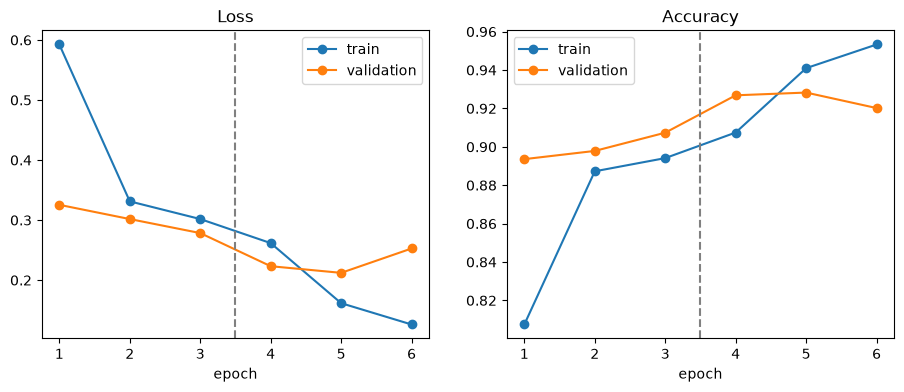

In [10]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')   # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.savefig(os.path.join(IMG_DIR, 'learning_curves.png'), dpi=130, bbox_inches='tight')
plt.show()

### Write it - Part 5
**Trainable parameters now:** **8,396,806** (layer4 = 8,393,728 + head 3,078), about 75% of the 11,179,590 total (the printout confirms 8,396,806).

**Did fine-tuning help?** Yes. Best validation accuracy rose from **0.907** (feature extraction) to **0.928** (fine-tuned, epoch 5): **+2.09 percentage points**. It cost more time: epochs took 1191 s, 2122 s and 2988 s because gradients now flow through layer4.

**What the curves show:** in epochs 1-3 (before the dashed line) training loss falls from 0.593 to 0.302 and validation loss from 0.325 to 0.278, while validation accuracy creeps from 0.894 to 0.907. After unfreezing layer4 (epochs 4-6), validation loss drops quickly to 0.223 and then 0.212, and validation accuracy jumps to 0.927 and 0.928. Training loss keeps falling to 0.126 and training accuracy rises to 0.953.

**Overfitting?** Yes, a mild sign at epoch 6: training loss keeps falling (0.162 -> 0.126) while validation loss rises (0.212 -> 0.253) and validation accuracy slips (0.928 -> 0.920), and the training accuracy (0.953) is now above the validation accuracy. Epoch 5 was the best, and `fit()` restored the epoch-5 weights, which is why the test is done with the best epoch. More epochs would likely overfit further.

**Why training accuracy can be LOWER than validation accuracy:** in epochs 1-4 training accuracy is below validation accuracy (0.807 vs 0.894, 0.887 vs 0.898, 0.894 vs 0.907, 0.907 vs 0.927). Training images are augmented (random crops that remove up to 30% of the image, flips, brightness and contrast jitter), so they are harder than the clean validation images. Also, training accuracy is averaged while the weights are still improving during the epoch, whereas validation is measured at the end with the model in `eval()` mode.

## Part 6: Test Once, Then Study the Errors

### Task 6.1: Test-set evaluation

Test accuracy: 0.929
              precision    recall  f1-score   support

   buildings      0.898     0.945     0.921       437
      forest      0.977     0.996     0.986       474
     glacier      0.914     0.863     0.887       553
    mountain      0.861     0.909     0.884       525
         sea      0.972     0.965     0.969       510
      street      0.960     0.910     0.934       501

    accuracy                          0.929      3000
   macro avg      0.930     0.931     0.930      3000
weighted avg      0.930     0.929     0.929      3000



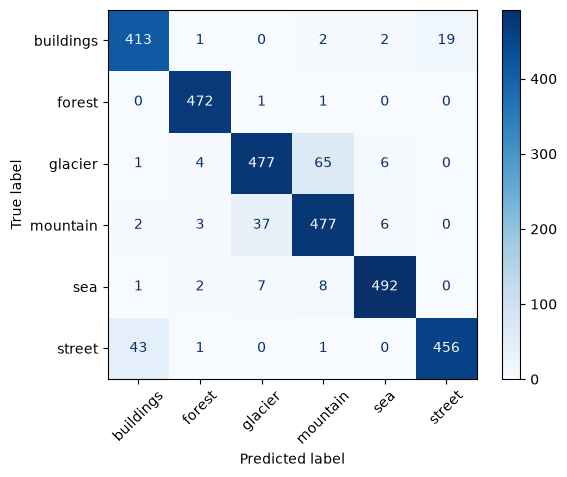

In [11]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)
test_acc = (preds == labels).float().mean().item()
print(f'Test accuracy: {test_acc:.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.savefig(os.path.join(IMG_DIR, 'confusion_matrix.png'), dpi=130, bbox_inches='tight')
plt.show()

### Helper: auto-find the weakest classes and the most confused pair (for your Write it answer)

In [12]:
recall = cm.diagonal() / cm.sum(axis=1)
order = np.argsort(recall)
print('Two weakest classes by recall:')
for i in order[:2]:
    print(f'  {classes[i]:10s} recall {recall[i]:.3f}')
off = cm.copy()
np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f'Most confused pair: true {classes[i]} -> predicted {classes[j]} ({off[i, j]} images)')

Two weakest classes by recall:
  glacier    recall 0.863
  mountain   recall 0.909
Most confused pair: true glacier -> predicted mountain (65 images)


### Task 6.2: Error gallery

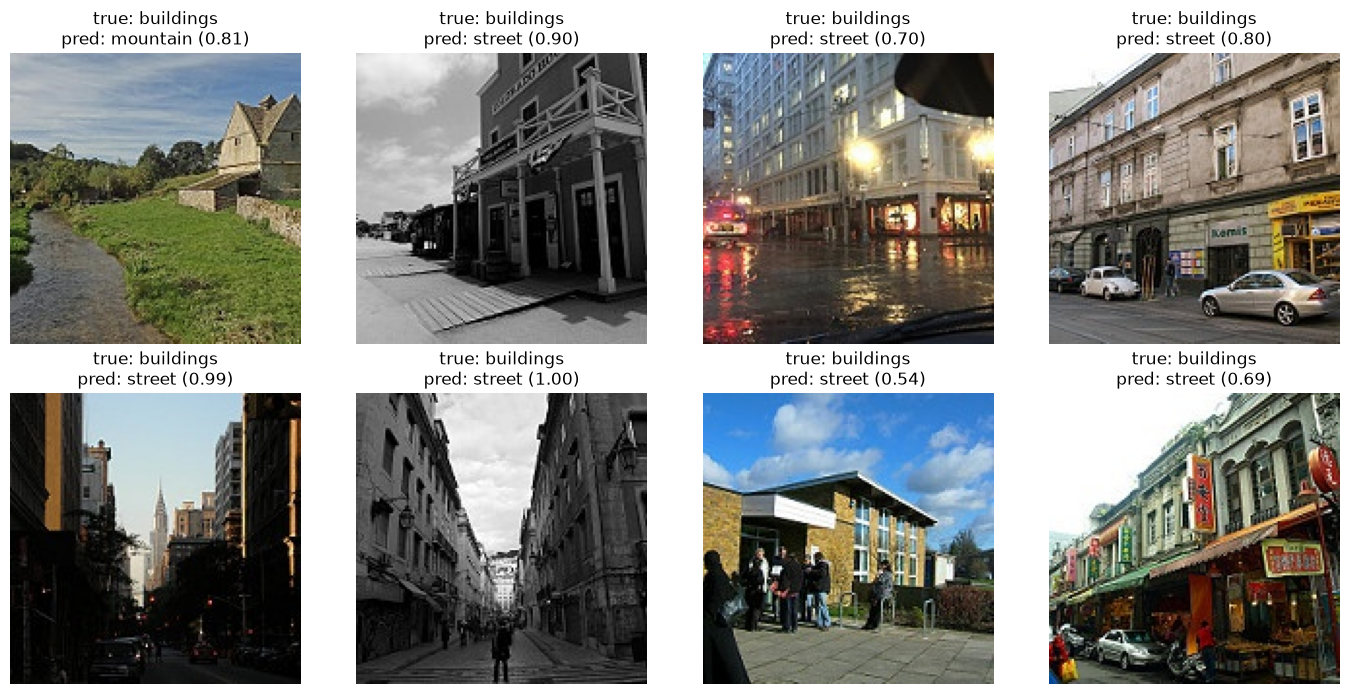

In [13]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, 'error_gallery.png'), dpi=130, bbox_inches='tight')
plt.show()

### Task 6.3: Inside one prediction

In [14]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')
print('Sum of probabilities:', p.sum().item())

True class: buildings
buildings  logit   8.79   probability 1.000
forest     logit  -9.56   probability 0.000
glacier    logit  -4.41   probability 0.000
mountain   logit  -5.07   probability 0.000
sea        logit  -6.11   probability 0.000
street     logit  -3.60   probability 0.000
Sum of probabilities: 0.9999999403953552


### Write it - Part 6
**Test accuracy (used once):** **92.9%**: 2,787 of 3,000 images correct, 213 errors. The test set was used once, after the best epoch was chosen on validation.

**Recall per class:** forest 0.996, sea 0.965, buildings 0.945, street 0.910, mountain 0.909, glacier 0.863. **Two weakest by recall: glacier (0.863) and mountain (0.909)**, with street (0.910) just behind. Mountain also has the lowest precision (0.861) because many glaciers are predicted as mountain. Macro F1 is 0.930.

**Most confused pair:** **true glacier predicted as mountain: 65 images** (the reverse, mountain -> glacier, is 37). Together glacier <-> mountain account for 102 of the 213 errors (48%). The second pair is street <-> buildings (43 + 19 = 62 errors, 29%). These two pairs make up 164 of 213 errors (77%). **My prediction from Task 1.2 (glacier vs mountain) was right.** Forest is almost perfect (472 of 474).

**Error gallery.** The gallery shows the first 8 errors in the test set. Because the test folder is sorted by class, all 8 are true *buildings* images (7 predicted street, 1 mountain), so it is not a random sample, but it matches the second-largest confusion. Numbering the images 1 to 8 in reading order:
1. **Image 1** (true buildings, predicted mountain, 0.81): a small stone house by a stream in a green valley with a hill behind. The image is **genuinely ambiguous**: it is mostly landscape and the building is a small part of it.
2. **Image 6** (true buildings, predicted street, 1.00): a black-and-white narrow alley between tall stone buildings with a pedestrian. This is **genuinely ambiguous, and the label is questionable**, because the photo is taken from street level; the model is fully confident in "street".
3. **Image 7** (true buildings, predicted street, 0.54): a modern building with people on the pavement in front and blue sky. Here the **model was wrong**: the building fills the frame and the label looks right; the low confidence (0.54) shows it was unsure.
4. **Image 3** (true buildings, predicted street, 0.70): a rainy night city street with wet road, car lights and tall buildings. **Ambiguous**: it is as much a street scene as a buildings scene.

**Lesson:** buildings and street overlap by definition (many "buildings" photos are taken from the street), and the model can be 0.99 to 1.00 confident on images that are wrong or ambiguous, so confidence is not correctness.

**Softmax on test image 0 (true class: buildings):** logits are buildings 8.79, forest -9.56, glacier -4.41, mountain -5.07, sea -6.11, street -3.60. Softmax computes p_i = e^(z_i) / sum(e^(z_j)). The biggest logit is 12.39 above the runner-up (street), so street gets only about e^(-12.39) = 4 x 10^-6, and buildings gets **1.000**; the probabilities sum to 1 (0.99999994 is float rounding). The method is the same as the hand-computed table in the lecture; here one logit dominates, so the output is almost one-hot (correct, and confident).

## Part 7: Save and Share

In [15]:
path = os.path.join(MODEL_DIR, 'resnet18_intel.pt')
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications\models\resnet18_intel.pt (44.8 MB)


### Write it - Part 7
**Saved model:** `models/resnet18_intel.pt`, **44.8 MB**, under GitHub's 100 MB file limit.

**Results summary**

| item | value |
|---|---|
| Dataset | Intel Image Classification, 6 classes, 14,034 train / 3,000 test |
| Split | 11,929 train / 2,105 val / 3,000 test |
| Model | ResNet-18 pretrained on ImageNet, CPU training |
| Feature extraction (3,078 trainable params, 3 epochs) | val accuracy 0.907 |
| Fine-tuning layer4 (8,396,806 trainable params, 3 epochs) | val accuracy 0.928 (+2.09 points) |
| Test accuracy (used once) | 0.929 |
| Weakest class | glacier (recall 0.863), confused with mountain (65 images) |

The README (with these numbers) are in the GitHub repo: `README.md`.

## Check Your Understanding

**1. Why does a network without nonlinear activations collapse to a single linear layer?**
Each layer computes W x + b. Stacking two gives W2 (W1 x + b1) + b2 = (W2 W1) x + (W2 b1 + b2), which is again one matrix times x plus one bias. A product of linear maps is linear, so any depth collapses to one linear layer. Nonlinearities such as ReLU between layers break this and let the network represent curved decision boundaries.

**2. For logits [3, 1, 0], what probability does softmax give the first class?**
e^3 = 20.0855, e^1 = 2.7183, e^0 = 1. Sum = 23.8038. P(class 1) = 20.0855 / 23.8038 = **0.844** (the others: 0.114 and 0.042).

**3. How many parameters does a 3 x 3 convolution from 64 to 128 channels have?**
(K x K x C_in + 1) x C_out = (3 x 3 x 64 + 1) x 128 = 577 x 128 = **73,856**.

**4. An input of 56 x 56 goes through a 3 x 3 convolution with padding 1 and stride 2. What is the output size?**
(W - K + 2P) / S + 1 = (56 - 3 + 2) / 2 + 1 = 55 / 2 + 1 = 27.5 + 1, rounded down to 27 + 1 = **28 x 28**.

**5. Why does a residual (skip) connection help gradients reach the early layers?**
A residual block computes y = F(x) + x, so dy/dx = dF/dx + 1. The "+1" is an identity path that carries the gradient straight back to earlier layers, even when dF/dx is small. This reduces vanishing gradients and makes very deep networks trainable.

**6. When would you train a CNN from scratch instead of using transfer learning?**
When the data is very different from natural photos (for example spectrograms, multi-channel satellite or medical scans) so ImageNet features do not transfer; when you have a very large labelled dataset; when the input format (channels/size) does not match a pretrained model; or when you need a much smaller custom model for a tight memory or latency budget.